CNN_Assignment

## 1. Libraries aur Google Drive

In [42]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import image_dataset_from_directory

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Dataset paths

In [43]:
train_dir = "/content/drive/MyDrive/Dataset for CNN/train"
test_dir = "/content/drive/MyDrive/Dataset for CNN/test"

# Path check: yahan 6 class folders nazar aane chahiye
print("Train classes:", sorted(os.listdir(train_dir)))
print("Test classes:", sorted(os.listdir(test_dir)))

Train classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Test classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## 3. Using `image_dataset_from_directory` to read images

Train folder mein har class ki 144 images hain: 100 training + 44 validation,
is liye `validation_split = 44/144`.

In [44]:
train_dataset = image_dataset_from_directory(
    train_dir,
    validation_split=44/144,
    subset="training",
    seed=123,
    image_size=(150, 150),
    batch_size=16)
validation_dataset = image_dataset_from_directory(
    train_dir,
    validation_split=44/144,
    subset="validation",
    seed=123,
    image_size=(150, 150),
    batch_size=16)
test_dataset = image_dataset_from_directory(
    test_dir,
    image_size=(150, 150),
    batch_size=16,
    shuffle=False)

class_names = train_dataset.class_names
print("Class names:", class_names)
assert len(class_names) == 6

Found 864 files belonging to 6 classes.
Using 600 files for training.
Found 864 files belonging to 6 classes.
Using 264 files for validation.
Found 600 files belonging to 6 classes.
Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


**Displaying the shapes of the data and labels yielded by the `Dataset`**

In [45]:
for data_batch, labels_batch in train_dataset:
    print("data batch shape:", data_batch.shape)
    print("labels batch shape:", labels_batch.shape)
    break

data batch shape: (16, 150, 150, 3)
labels batch shape: (16,)


## 4. Data augmentation stage

Assignment ke parameters: RandomFlip vertical, RandomRotation 0.3, RandomZoom 0.3.

In [46]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("vertical"),
        layers.RandomRotation(0.3),
        layers.RandomZoom(0.3),
    ]
)

**Displaying some randomly augmented training images**

## 5. CNN banane ka function

32 -> 64 -> 128 -> 256 -> 512 -> 1024, kernel_size=3, pool_size=2, padding="same".
Ek hi function se dono models (normal aur augmented) banenge.

In [47]:
def build_cnn(augment=False, dropout=False):
    inputs = keras.Input(shape=(150, 150, 3))
    x = data_augmentation(inputs) if augment else inputs
    x = layers.Rescaling(1./255)(x)
    x = layers.Conv2D(filters=32, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=64, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=128, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=256, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=512, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(filters=1024, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.Flatten()(x)
    if dropout:
        x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(6, activation="softmax")(x)
    model = keras.Model(inputs=inputs, outputs=outputs)
    # labels integer hain (image_dataset_from_directory default), is liye sparse loss
    model.compile(loss="sparse_categorical_crossentropy",
                  optimizer="rmsprop",
                  metrics=["accuracy"])
    return model

def plot_curves(history, name):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(1, len(accuracy) + 1)
    plt.plot(epochs, accuracy, "bo", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
    plt.title(f"Training and validation accuracy - {name}")
    plt.legend()
    plt.figure()
    plt.plot(epochs, loss, "bo", label="Training loss")
    plt.plot(epochs, val_loss, "b", label="Validation loss")
    plt.title(f"Training and validation loss - {name}")
    plt.legend()
    plt.show()

model = build_cnn(augment=False, dropout=False)
model.summary()

Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_9 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_54 (Conv2D)              │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_55 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_56 (Conv2D)              │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_57 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_48 (MaxPooling2D) │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_58 (Conv2D)              │ (None, 9, 9, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_49 (MaxPooling2D) │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_59 (Conv2D)              │ (None, 4, 4, 1024)     │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │        98,310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,386,502 (24.36 MB)

 Trainable params: 6,386,502 (24.36 MB)

 Non-trainable params: 0 (0.00 B)

## 6. First CNN ko 20 epochs train karein

In [48]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",
        save_best_only=True,
        monitor="val_loss")
]
history = model.fit(
    train_dataset,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 9s 164ms/step - accuracy: 0.1750 - loss: 1.8375 - val_accuracy: 0.1553 - val_loss: 1.7798
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.2850 - loss: 1.7790 - val_accuracy: 0.2955 - val_loss: 1.4873
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.3950 - loss: 1.5273 - val_accuracy: 0.4659 - val_loss: 1.3253
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.4633 - loss: 1.3368 - val_accuracy: 0.4962 - val_loss: 1.2315
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.5100 - loss: 1.2785 - val_accuracy: 0.5417 - val_loss: 1.1882
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.5483 - loss: 1.1617 - val_accuracy: 0.4924 - val_loss: 1.2722
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.5683 - loss: 1.1078 - val_accuracy: 0.6061 - val_loss: 1.0342
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.5717 - loss: 1.0326 - val_accuracy: 0.5530 - 

## 7. Training / Validation curves

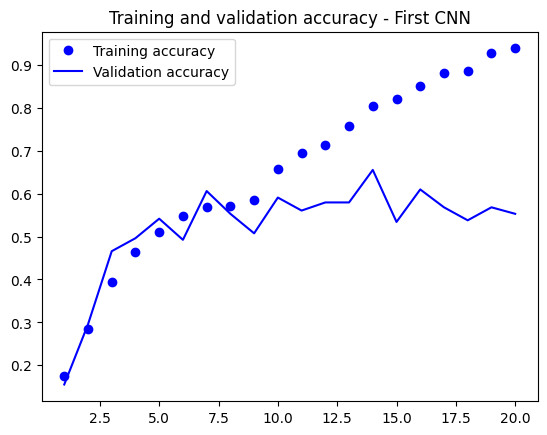

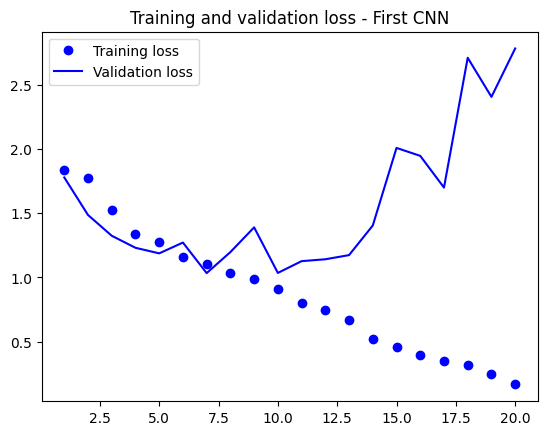

In [49]:
plot_curves(history, "First CNN")

## 8. Sab se behtareen validation epoch (elbow)

Graph dekh kar elbow epoch batayein. Neeche ka code sirf numerical check hai.

In [50]:
best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1
print("Epoch with highest validation accuracy:", best_epoch)
print(f"Highest validation accuracy: {history.history['val_accuracy'][best_epoch - 1]:.3f}")

Epoch with highest validation accuracy: 14
Highest validation accuracy: 0.655


## 9. First CNN ko selected epoch tak dobara train karein

Agar graph mein elbow kisi aur epoch pe hai to `selected_epoch` badal dein.

In [51]:
selected_epoch = best_epoch

model_retrained = build_cnn(augment=False, dropout=False)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_retrained.keras",
        save_best_only=True,
        monitor="val_loss")
]
history_retrained = model_retrained.fit(
    train_dataset,
    epochs=selected_epoch,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/14
38/38 ━━━━━━━━━━━━━━━━━━━━ 9s 163ms/step - accuracy: 0.1417 - loss: 1.9568 - val_accuracy: 0.1591 - val_loss: 1.7897
Epoch 2/14
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.1950 - loss: 1.8225 - val_accuracy: 0.3826 - val_loss: 1.7038
Epoch 3/14
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.3500 - loss: 1.9460 - val_accuracy: 0.4735 - val_loss: 1.4166
Epoch 4/14
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.4200 - loss: 1.4305 - val_accuracy: 0.2614 - val_loss: 2.3982
Epoch 5/14
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.4833 - loss: 1.4295 - val_accuracy: 0.4735 - val_loss: 1.5692
Epoch 6/14
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.5083 - loss: 1.2680 - val_accuracy: 0.4356 - val_loss: 1.4987
Epoch 7/14
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5483 - loss: 1.1586 - val_accuracy: 0.5076 - val_loss: 1.2591
Epoch 8/14
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.5717 - loss: 1.0882 - val_accuracy: 0.5417 - 

## 10. First CNN ko test set par evaluate karein

In [52]:
test_model = keras.models.load_model("convnet_from_scratch_retrained.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"First CNN Test accuracy: {test_acc:.3f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.5833 - loss: 1.0614
First CNN Test accuracy: 0.583


## 11. Augmented CNN (augmentation + Dropout 0.5)

In [53]:
model_aug = build_cnn(augment=True, dropout=True)
model_aug.summary()

Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_11 (Rescaling)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_66 (Conv2D)              │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_55 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_67 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_56 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_68 (Conv2D)              │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_57 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_69 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_58 (MaxPooling2D) │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_70 (Conv2D)              │ (None, 9, 9, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_59 (MaxPooling2D) │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_71 (Conv2D)              │ (None, 4, 4, 1024)     │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │        98,310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,386,502 (24.36 MB)

 Trainable params: 6,386,502 (24.36 MB)

 Non-trainable params: 0 (0.00 B)

## 12. Augmented model ko 20 epochs train karein

In [54]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation.keras",
        save_best_only=True,
        monitor="val_loss")
]
history_aug = model_aug.fit(
    train_dataset,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.1767 - loss: 1.8286 - val_accuracy: 0.2500 - val_loss: 1.7587
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.2467 - loss: 1.7711 - val_accuracy: 0.3144 - val_loss: 1.4855
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.3300 - loss: 1.6089 - val_accuracy: 0.1970 - val_loss: 1.5700
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.3267 - loss: 1.6521 - val_accuracy: 0.1439 - val_loss: 3.8178
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.3733 - loss: 1.5263 - val_accuracy: 0.2197 - val_loss: 1.7494
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.3417 - loss: 1.5292 - val_accuracy: 0.4356 - val_loss: 1.3525
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.4067 - loss: 1.4903 - val_accuracy: 0.4697 - val_loss: 1.3831
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.4250 - loss: 1.4421 - val_accuracy: 0.3864 - v

## 13. Augmented model ke curves

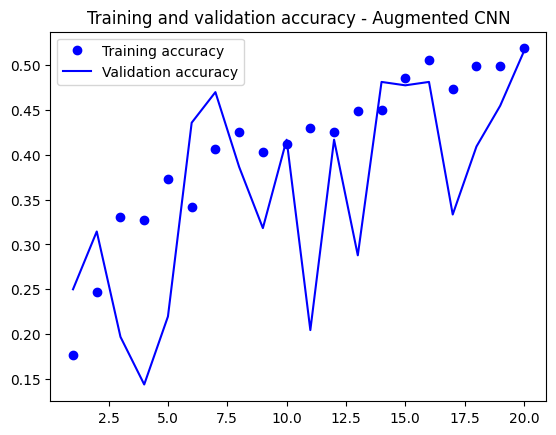

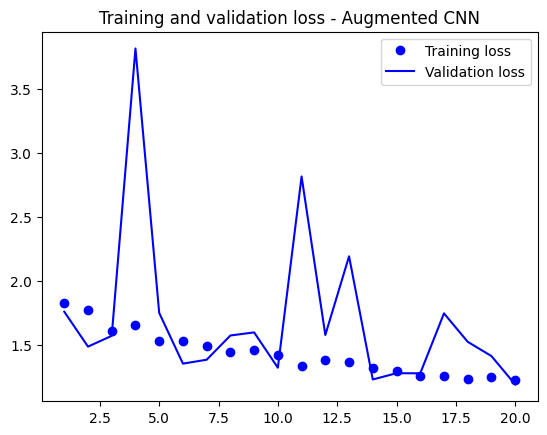

In [55]:
plot_curves(history_aug, "Augmented CNN")

## 14. Augmented model ka best validation epoch

In [56]:
best_epoch_aug = int(np.argmax(history_aug.history["val_accuracy"])) + 1
print("Epoch with highest validation accuracy:", best_epoch_aug)
print(f"Highest validation accuracy: {history_aug.history['val_accuracy'][best_epoch_aug - 1]:.3f}")

Epoch with highest validation accuracy: 20
Highest validation accuracy: 0.515


## 15. Augmented model ko selected epoch tak dobara train karein

In [57]:
selected_epoch_aug = best_epoch_aug

model_aug_retrained = build_cnn(augment=True, dropout=True)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation_retrained.keras",
        save_best_only=True,
        monitor="val_loss")
]
history_aug_retrained = model_aug_retrained.fit(
    train_dataset,
    epochs=selected_epoch_aug,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.1717 - loss: 1.9988 - val_accuracy: 0.3106 - val_loss: 1.6723
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.2333 - loss: 1.7638 - val_accuracy: 0.3144 - val_loss: 1.6649
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.2767 - loss: 1.6882 - val_accuracy: 0.3864 - val_loss: 1.6030
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.3300 - loss: 1.6649 - val_accuracy: 0.2803 - val_loss: 1.5363
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.3467 - loss: 1.5320 - val_accuracy: 0.2538 - val_loss: 2.5057
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.4217 - loss: 1.4769 - val_accuracy: 0.2462 - val_loss: 2.4327
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.3600 - loss: 1.5784 - val_accuracy: 0.3902 - val_loss: 1.4179
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.3767 - loss: 1.4420 - val_accuracy: 0.4280 - v

## 16. Augmented CNN ko test set par evaluate karein

In [58]:
test_model_aug = keras.models.load_model(
    "convnet_from_scratch_with_augmentation_retrained.keras")
test_loss_aug, test_acc_aug = test_model_aug.evaluate(test_dataset)
print(f"Augmented CNN Test accuracy: {test_acc_aug:.3f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.5300 - loss: 1.1998
Augmented CNN Test accuracy: 0.530


## 17. Dono models ka comparison

In [59]:
print("===== MODEL COMPARISON =====")
print(f"First CNN Test accuracy:     {test_acc:.3f}")
print(f"Augmented CNN Test accuracy: {test_acc_aug:.3f}")

===== MODEL COMPARISON =====
First CNN Test accuracy:     0.583
Augmented CNN Test accuracy: 0.530


## 18. Opinion / Discussion

The first CNN got 0.583 test accuracy and the augmented CNN got 0.530, so
augmentation and Dropout did not improve the result in my run. The
difference is small, so both models perform about the same.

Reason: the dataset is small (100 training images per class) and the model
is large. Also, strong augmentation (like vertical flip) creates unrealistic
images, and augmentation with Dropout makes learning slower in only 20
epochs. So the augmented model could not show a clear benefit.
## 19. Nayi image ki class predict karein

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
Predicted class: mountain
Prediction probabilities:
buildings: 0.0409
forest: 0.0335
glacier: 0.1345
mountain: 0.4700
sea: 0.3078
street: 0.0132


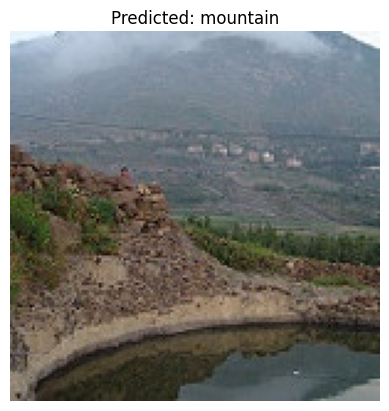

In [60]:
image_path = "/content/drive/MyDrive/Dataset for CNN/test/mountain/20058.jpg"   # <-- apni image ka path

assert os.path.exists(image_path), "Image nahi mili, image_path check karein."

img = keras.utils.load_img(image_path, target_size=(150, 150))
img_array = keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

predictions = test_model_aug.predict(img_array)
predicted_class = np.argmax(predictions[0])

print("Predicted class:", class_names[predicted_class])
print("Prediction probabilities:")
for class_name, probability in zip(class_names, predictions[0]):
    print(f"{class_name}: {probability:.4f}")

plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {class_names[predicted_class]}")
plt.show()